In [117]:
### Imports and Libraries

import os
import pickle
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from shapely.geometry import box
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import GroupKFold

# Import sorted data for section of choice
section_name = "Middle"
csv_path = f"../sorted_data/complete_data_{section_name}.csv"
complete_data = pd.read_csv(csv_path)
complete_data_crs = "ESRI:102690"

# filter out the northern-most transect manually, remove points above 321000 ft
complete_data = complete_data[complete_data["Northing"] < 321000]

if "Sontek" not in complete_data.columns:
    raise KeyError(
        f"{csv_path} has no 'Sontek' column. Re-run dataSorting.ipynb from the ADCP cell "
        "through the CSV export, then re-run this cell."
    )


Original centerline CRS: EPSG:4269
Original Middle Data CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",41.5],PARAMETER["central_meridian",-84.3666666666667],PARAMETER["standard_parallel_1",42.1],PARAMETER["standard_parallel_2",43.6666666666667],PARAMETER["false_easting",13123333.3333333],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102690"]]
Converted centerline CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AU

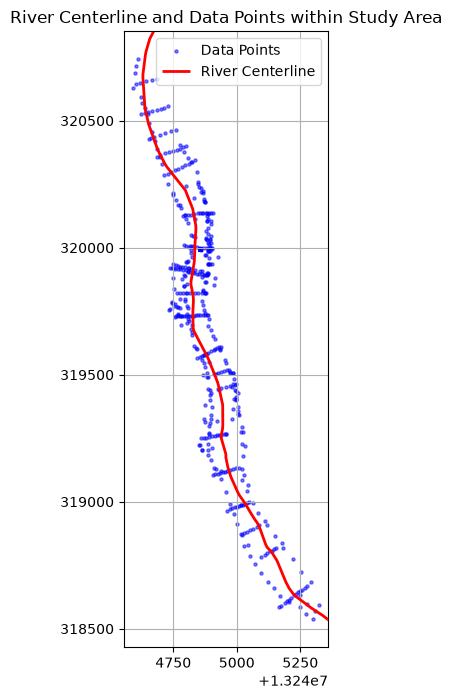

In [118]:
### Centerline Import and Trimming

# Import centerline GeoJSON
centerline = gpd.read_file("../mapping/Huron_RiverSystem.geojson")
print(f"Original centerline CRS: {centerline.crs}")

# Import Middle Data GeoJSON
df_Middle = gpd.read_file("../mapping/data_Middle.geojson")
print(f"Original Middle Data CRS: {df_Middle.crs}")

# Convert centerline CRS to match complete_data CRS
centerline = centerline.to_crs(df_Middle.crs)
print(f"Converted centerline CRS: {centerline.crs}")

### Trim the Massive Centerline File to Match Data Size
# Get the min/max bounds of Easting (X) and Northing (Y) columns
x_min = complete_data["Easting"].min()
x_max = complete_data["Easting"].max()
y_min = complete_data["Northing"].min()
y_max = complete_data["Northing"].max()

print("\nData bounds:")
print(f"X: {x_min:.1f} to {x_max:.1f}")
print(f"Y: {y_min:.1f} to {y_max:.1f}")

# Create a bounding box polygon using (minx, miny, maxx, maxy)
bbox = box(x_min, y_min, x_max, y_max)

# Clip centerline to data bounds
centerline_clipped = centerline[centerline.geometry.intersects(bbox)]

print(f"\nCenterline features reduced from {len(centerline)} to {len(centerline_clipped)}")

# Update centerline variable to use clipped version
centerline = centerline_clipped

### Visualize the Centerline and Data Overlapped
# Create a bounding box for visualization
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox], crs=complete_data_crs)

# Create figure and axis
fig, ax = plt.subplots(figsize=(15, 8))

# Plot the trimmed data points (same rows as dataSorting GeoJSON / later GP cells)
scatter = ax.scatter(complete_data["Easting"], complete_data["Northing"], color='blue', alpha=0.5, s=5, label='Data Points')

# Plot the centerline
centerline.plot(ax=ax, color='red', linewidth=2, label='River Centerline')

# Set the plot bounds to match the bbox bounds with small buffer
bbox_minx, bbox_miny, bbox_maxx, bbox_maxy = bbox.bounds
x_buffer = (bbox_maxx - bbox_minx) * 0.05  # 5% buffer
y_buffer = (bbox_maxy - bbox_miny) * 0.05  # 5% buffer
ax.set_xlim(bbox_minx - x_buffer, bbox_maxx + x_buffer)
ax.set_ylim(bbox_miny - y_buffer, bbox_maxy + y_buffer)

# Add title and legend
plt.title('River Centerline and Data Points within Study Area')
plt.legend()

# Add gridlines
ax.grid(True)

# Show the plot
plt.show()


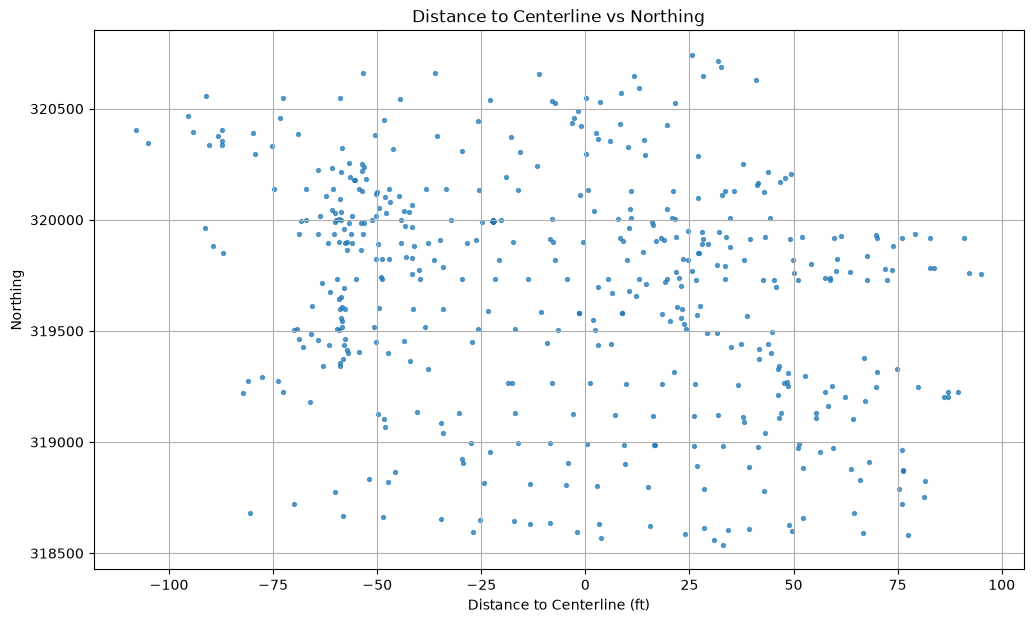

In [119]:
### Load Precomputed Distance to Centerline
# Distances are computed once in dataSorting.ipynb
# Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['distance_to_centerline'], complete_data['Northing'], s=8, alpha=0.7)
plt.xlabel("Distance to Centerline (ft)")
plt.ylabel("Northing")
plt.title("Distance to Centerline vs Northing")
plt.grid(True)
plt.show()

Reference Distance for Calc = 3781.94 feet

Downstream distances loaded for 940 points
Distance range: 0.0 to 2367.7 feet
All distances are non-negative (as expected)


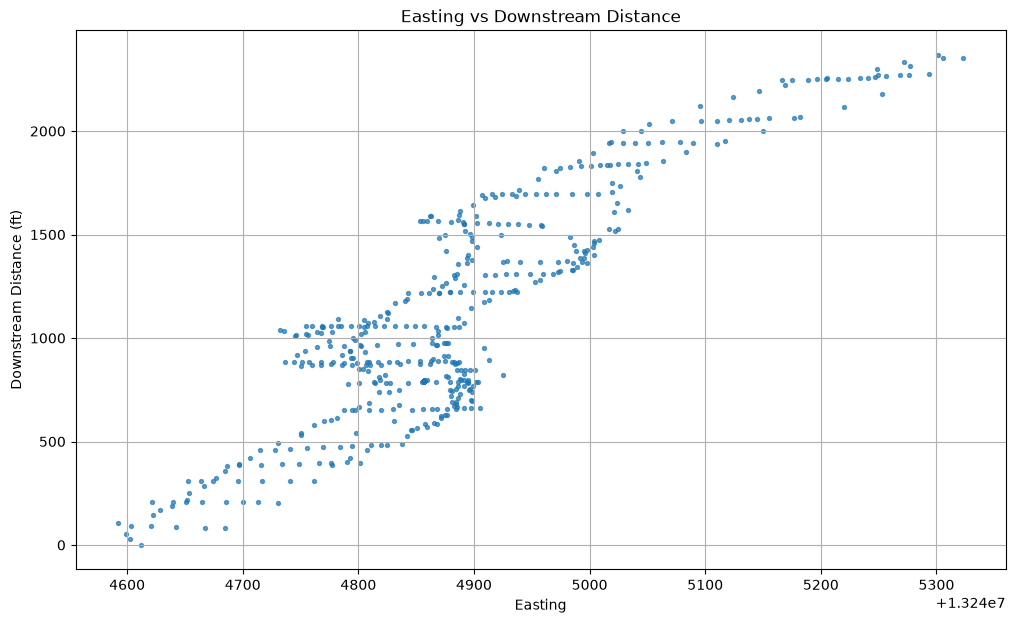

In [120]:
### Downstream Distance
# downstream_dist is computed in dataSorting.ipynb.
# To translate the model results back to coordinates, rebuild the SAME main-stem
# centerline as dataSorting (section bbox + 500 ft buffer + build_main_stem). The absolute
# projected distance is stored in 'dist_along_centerline', so the reference is recoverable
# directly from the data (it is the same constant for every row):
reference_distance = (complete_data['dist_along_centerline'] - complete_data['downstream_dist']).iloc[0]
# MAKE SURE THIS IS THE SAME REFERENCE POINT WHICH IS USED LATER FOR TRANSLATION OF MODEL BACK TO LAT LONG!

print(f"Reference Distance for Calc = {reference_distance:.2f} feet")

valid_downstream = complete_data['downstream_dist'].dropna()
print(f"\nDownstream distances loaded for {valid_downstream.size} points")
print(f"Distance range: {valid_downstream.min():.1f} to {valid_downstream.max():.1f} feet")

# Verify no negative distances (the 150 ft filter above removed any point upstream of the reference)
negative_count = (valid_downstream < -0.01).sum()  # Allow small floating point errors
if negative_count > 0:
    print(f"WARNING: {negative_count} points have negative distances (should be 0)")
else:
    print("All distances are non-negative (as expected)")

# Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['Easting'], complete_data['downstream_dist'], s=8, alpha=0.7)
plt.xlabel("Easting")
plt.ylabel("Downstream Distance (ft)")
plt.title("Easting vs Downstream Distance")
plt.grid(True)
plt.show()


In [121]:
### 3 Input GP (Sontek data omitted) — calibrated uncertainty, no mean correction
# Focus: honest predictive uncertainty rather than correcting the target mean.
#   1. vel_1 is left UNCORRECTED (no flat shift -> no risk of negative velocities).
#   2. Log-law points get INFLATED noise (alpha), reflecting the known method bias
#      as added variance rather than a mean edit.
#   3. Leave-one-survey-day-out CV now also collects the GP's own predictive std
#      per held-out point, not just point predictions.
#   4. Standardized residuals from that CV (z = (y_true - y_pred) / y_std_gp) are
#      used to compute a calibration factor lambda -- both globally and split by
#      year -- since the model's raw posterior std is expected to be too narrow
#      given the known non-stationarity between seasons.
#   5. The final model's reported uncertainty is scaled by lambda before use.
import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

FT_TO_M = 0.3048

print("="*80)
print("3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)")
print("CALIBRATED UNCERTAINTY (target left uncorrected; noise inflated for method bias)")
print("="*80)

input_columns_3v = ['upstream_depth', 'downstream_dist', 'distance_to_centerline']
output_column_3v = 'vel_1'

is_sontek = complete_data['Type'].astype(str).str.strip().str.lower().eq('sontek')
n_sontek = int(is_sontek.sum())

gp_data_3v = complete_data[
    complete_data[input_columns_3v[0]].notna() &
    complete_data[input_columns_3v[1]].notna() &
    complete_data[input_columns_3v[2]].notna() &
    complete_data[output_column_3v].notna() &
    ~is_sontek
].copy()

gp_data_3v['survey_day'] = pd.to_datetime(gp_data_3v['Collection Date']).dt.date
gp_data_3v['year'] = pd.to_datetime(gp_data_3v['Collection Date']).dt.year

print(f"\nData Summary:")
print(f"  Total points in streambed dataset: {len(complete_data)}")
print(f"  Sontek/ADCP rows excluded: {n_sontek}")
print(f"  Points used for GP training: {len(gp_data_3v)}")
print(f"  Unique survey days: {gp_data_3v['survey_day'].nunique()}")
if gp_data_3v['Type'].astype(str).str.strip().str.lower().eq('sontek').any():
    raise ValueError("Sontek rows are still present in gp_data_3v; they must not be used for GP training.")

print(f"\nConverting units from Imperial to SI...")
for col in input_columns_3v:
    gp_data_3v[col] = gp_data_3v[col] * FT_TO_M
gp_data_3v[output_column_3v] = gp_data_3v[output_column_3v] * FT_TO_M   # target left as-is from here on
gp_data_3v['vel_1_sd_si'] = gp_data_3v['vel_1_sd'] * FT_TO_M
print(f"DataFrame converted to SI units")

gp_data_3v['method_loglaw'] = (gp_data_3v['vel_1_sd_si'] > 0).astype(int)

# ---------------------------------------------------------------------------
# Estimate the method bias (2025 only, both methods coexist, year held fixed)
# -- used ONLY to inflate alpha for log-law points, never to shift vel_1.
# ---------------------------------------------------------------------------
bias_fit_data = gp_data_3v[gp_data_3v['year'] == 2025].copy()
Xb = np.column_stack([
    np.ones(len(bias_fit_data)),
    bias_fit_data['downstream_dist'].to_numpy(),
    bias_fit_data['distance_to_centerline'].to_numpy(),
    bias_fit_data['upstream_depth'].to_numpy(),
    bias_fit_data['method_loglaw'].to_numpy(dtype=float),
])
yb = bias_fit_data[output_column_3v].to_numpy()
coefs, _, _, _ = np.linalg.lstsq(Xb, yb, rcond=None)
n_obs, n_params = Xb.shape
resid = yb - Xb @ coefs
dof = n_obs - n_params
sigma2 = np.sum(resid ** 2) / dof
XtX_inv = np.linalg.inv(Xb.T @ Xb)
se = np.sqrt(np.diag(sigma2 * XtX_inv))
method_bias = coefs[-1]
method_bias_se = se[-1]

print(f"\n=== Measurement-method bias (used for noise inflation only, target NOT shifted) ===")
print(f"  Estimated from 2025 data only (n={len(bias_fit_data)})")
print(f"  Log-law vs direct offset: {method_bias:+.4f} m/s (SE = {method_bias_se:.4f})")
print(f"  vel_1 range (unmodified): [{gp_data_3v[output_column_3v].min():.3f}, "
      f"{gp_data_3v[output_column_3v].max():.3f}] m/s -- confirms no negative-velocity artifacts")

X_3v = gp_data_3v[input_columns_3v].values
y_3v = gp_data_3v[output_column_3v].values
print(f"\nFeature shapes: X {X_3v.shape}, y {y_3v.shape}")

# alpha: base measurement noise + inflation for known, uncorrected method bias
# (bias^2 as excess variance, plus its own estimation uncertainty)
alpha_si = gp_data_3v['vel_1_sd_si'].to_numpy(dtype=float) ** 2 + 1e-6
loglaw_mask = gp_data_3v['method_loglaw'] == 1
alpha_si[loglaw_mask] += method_bias ** 2 + method_bias_se ** 2
print(f"  Log-law points with inflated alpha: {int(loglaw_mask.sum())} / {len(gp_data_3v)}")
print(f"  Mean alpha, direct points:  {alpha_si[~loglaw_mask].mean():.2e} (m/s)^2")
print(f"  Mean alpha, log-law points: {alpha_si[loglaw_mask].mean():.2e} (m/s)^2  "
      f"(inflated by known bias, not corrected in the mean)")

kernel_3v = C(1.0, (1e-2, 20)) * Matern(
    length_scale=[1.0, 1.0, 1.0],
    length_scale_bounds=[(0.01, 10.0), (0.01, 10.0), (0.01, 5.0)],
    nu=1.5
)

# ===========================================================================
# Leave-One-Survey-Day-Out CV -- now also collecting predictive std per point
# ===========================================================================
print("\n" + "-"*80)
print("Performing Leave-One-Survey-Day-Out Cross-Validation (collecting predictive std)...")
print("-"*80)

day_groups_raw = gp_data_3v['survey_day'].to_numpy()
unique_days = np.unique(day_groups_raw)
n_day_folds = len(unique_days)
day_to_idx = {d: i for i, d in enumerate(unique_days)}
day_groups = np.array([day_to_idx[d] for d in day_groups_raw])
years_arr = gp_data_3v['year'].to_numpy()

gkf = GroupKFold(n_splits=n_day_folds)
cv_r2_scores, cv_rmse_scores, cv_mae_scores, cv_fold_years = [], [], [], []
y_pred_cv = np.full(len(y_3v), np.nan, dtype=float)
y_std_cv = np.full(len(y_3v), np.nan, dtype=float)   # GP's own posterior std, held-out

for fold_idx, (train_idx, val_idx) in enumerate(gkf.split(X_3v, y_3v, groups=day_groups)):
    if len(val_idx) < 2:
        print(f"  Fold {fold_idx + 1} (day {unique_days[day_groups[val_idx][0]]}): "
              f"SKIPPED, n_val={len(val_idx)} < 2")
        continue

    X_train_cv, X_val_cv = X_3v[train_idx], X_3v[val_idx]
    y_train_cv, y_val_cv = y_3v[train_idx], y_3v[val_idx]

    scaler_X_cv, scaler_y_cv = StandardScaler(), StandardScaler()
    X_train_scaled_cv = scaler_X_cv.fit_transform(X_train_cv)
    y_train_scaled_cv = scaler_y_cv.fit_transform(y_train_cv.reshape(-1, 1)).ravel()
    X_val_scaled_cv = scaler_X_cv.transform(X_val_cv)
    alpha_train = alpha_si[train_idx] / (scaler_y_cv.scale_ ** 2)

    gp_cv = GaussianProcessRegressor(kernel=kernel_3v, n_restarts_optimizer=15,
                                      alpha=alpha_train, normalize_y=False, random_state=42)
    gp_cv.fit(X_train_scaled_cv, y_train_scaled_cv)

    y_val_pred_scaled, y_val_std_scaled = gp_cv.predict(X_val_scaled_cv, return_std=True)
    y_val_pred = scaler_y_cv.inverse_transform(y_val_pred_scaled.reshape(-1, 1)).ravel()
    y_val_std = y_val_std_scaled * scaler_y_cv.scale_   # back to raw m/s units

    y_pred_cv[val_idx] = y_val_pred
    y_std_cv[val_idx] = y_val_std

    fold_r2 = r2_score(y_val_cv, y_val_pred)
    fold_rmse = np.sqrt(mean_squared_error(y_val_cv, y_val_pred))
    fold_mae = mean_absolute_error(y_val_cv, y_val_pred)
    cv_r2_scores.append(fold_r2); cv_rmse_scores.append(fold_rmse); cv_mae_scores.append(fold_mae)

    held_out_day = unique_days[day_groups[val_idx][0]]
    held_out_year = years_arr[val_idx][0]
    cv_fold_years.append(held_out_year)
    print(f"  Fold {fold_idx + 1} (day {held_out_day}, {held_out_year}, n_train={len(train_idx)}, "
          f"n_val={len(val_idx)}): R2 = {fold_r2:.4f}, RMSE = {fold_rmse:.4f}, "
          f"mean predicted std = {y_val_std.mean():.4f}")

cv_r2_scores = np.array(cv_r2_scores)
cv_fold_years = np.array(cv_fold_years)

print("\n" + "="*80)
print("LEAVE-ONE-SURVEY-DAY-OUT CV RESULTS")
print("="*80)
print(f"  Overall R2:  mean = {cv_r2_scores.mean():.4f}, median = {np.median(cv_r2_scores):.4f}")
print(f"  Overall RMSE: {np.mean(cv_rmse_scores):.4f} +/- {np.std(cv_rmse_scores):.4f}")
for yr in sorted(set(cv_fold_years)):
    mask = cv_fold_years == yr
    print(f"  {yr} folds (n={mask.sum()}): R2 mean = {cv_r2_scores[mask].mean():.4f}")

# ===========================================================================
# UNCERTAINTY CALIBRATION from CV standardized residuals
# ===========================================================================
print("\n" + "="*80)
print("UNCERTAINTY CALIBRATION (from leave-one-day-out CV)")
print("="*80)

valid = ~np.isnan(y_pred_cv) & ~np.isnan(y_std_cv) & (y_std_cv > 0)
resid_cv = y_3v[valid] - y_pred_cv[valid]
std_cv = y_std_cv[valid]
z = resid_cv / std_cv

lambda_global = np.sqrt(np.mean(z ** 2))
print(f"  Points used for calibration: {valid.sum()}")
print(f"  Mean CV-reported posterior std: {std_cv.mean():.4f} m/s")
print(f"  Actual CV RMSE (same points):   {np.sqrt(np.mean(resid_cv**2)):.4f} m/s")
print(f"  Standardized residual std (should be ~1.0 if calibrated): {z.std():.4f}")
print(f"  --> GLOBAL calibration factor lambda = {lambda_global:.3f}  "
      f"(multiply posterior std by this)")

lambda_by_year = {}
years_valid = years_arr[valid]
for yr in sorted(set(years_valid)):
    m = years_valid == yr
    lam = np.sqrt(np.mean(z[m] ** 2))
    lambda_by_year[yr] = lam
    print(f"  {yr}-only calibration factor lambda = {lam:.3f}  (n={m.sum()})")

print(f"\n  NOTE: lambda >> 1 confirms the model's raw posterior std understates real error.")
print(f"  Apply lambda_global for a single blended interval, or lambda_by_year if you can")
print(f"  say which regime a new prediction point belongs to (safer, since the two years")
print(f"  are not equally well-calibrated by a single factor).")

# ===========================================================================
# Final model fit (all data, uncorrected target, inflated alpha)
# ===========================================================================
print("\n" + "-"*80)
print("Training Final Model on All Data (for predictions)...")
print("-"*80)

scaler_X_3v, scaler_y_3v = StandardScaler(), StandardScaler()
X_scaled_3v = scaler_X_3v.fit_transform(X_3v)
y_scaled_3v = scaler_y_3v.fit_transform(y_3v.reshape(-1, 1)).ravel()
alpha_all = alpha_si / (scaler_y_3v.scale_ ** 2)

gp_model_3v = GaussianProcessRegressor(kernel=kernel_3v, n_restarts_optimizer=15,
                                        alpha=alpha_all, normalize_y=False, random_state=42)
gp_model_3v.fit(X_scaled_3v, y_scaled_3v)
print(f"Final model trained successfully!")
print(f"Optimized kernel: {gp_model_3v.kernel_}")

# Length scales come out of gp_model_3v.kernel_ in STANDARDIZED units (because
# X_3v was scaled before fitting). To get them in physical units, multiply by
# each feature's StandardScaler scale_ (the std-dev it was divided by).
matern_3v = gp_model_3v.kernel_.k2  # k1 is the ConstantKernel, k2 is the Matern
length_scales_std = np.atleast_1d(matern_3v.length_scale)
length_scales_phys = length_scales_std * scaler_X_3v.scale_

print(f"\nLength scales (standardized units): {length_scales_std}")
print(f"Length scales (physical units, m):")
for name, ls in zip(input_columns_3v, length_scales_phys):
    print(f"  {name:<24s}: {ls:.4f} m")

y_pred_scaled_3v, y_std_scaled_3v = gp_model_3v.predict(X_scaled_3v, return_std=True)
y_pred_3v = scaler_y_3v.inverse_transform(y_pred_scaled_3v.reshape(-1, 1)).ravel()
y_std_3v_insample = y_std_scaled_3v * scaler_y_3v.scale_   # NOTE: on training points -- not the honest number, see below

print(f"\nTraining set R2 (reference only): {r2_score(y_3v, y_pred_3v):.4f}")

# ---------------------------------------------------------------------------
# CV-DERIVED CALIBRATED UNCERTAINTY -- this is the number to report, not the
# final model's in-sample std above. y_std_cv comes from the leave-one-day-out
# loop, so it already reflects genuine held-out prediction, and lambda corrects
# its remaining under-confidence. The in-sample std on training points will
# always look artificially small (a GP collapses toward its noise floor at
# points it has already seen) and is NOT comparable to the CV RMSE -- shown
# here only as a contrast, not as something to calibrate.
# ---------------------------------------------------------------------------
mean_cv_std_raw = y_std_cv[valid].mean()
mean_cv_std_calibrated_global = mean_cv_std_raw * lambda_global

print(f"\n=== CV-derived calibrated uncertainty (the number to report) ===")
print(f"  Mean held-out posterior std, RAW:              {mean_cv_std_raw:.4f} m/s")
print(f"  Mean held-out posterior std, CALIBRATED (x{lambda_global:.2f}): "
      f"{mean_cv_std_calibrated_global:.4f} m/s")
print(f"  Actual leave-one-day-out RMSE (same points):    "
      f"{np.sqrt(np.mean(resid_cv**2)):.4f} m/s")
print(f"  --> calibrated std vs. actual RMSE should now agree closely, "
      f"since both are genuinely out-of-sample")

print(f"\n  By-year breakdown (use whichever matches the regime of a new prediction):")
for yr in sorted(lambda_by_year.keys()):
    m = years_valid == yr
    mean_std_yr = y_std_cv[valid][m].mean()
    rmse_yr = np.sqrt(np.mean(resid_cv[m] ** 2))
    print(f"    {yr}: mean held-out std (raw) = {mean_std_yr:.4f}, "
          f"calibrated (x{lambda_by_year[yr]:.2f}) = {mean_std_yr * lambda_by_year[yr]:.4f}, "
          f"actual RMSE = {rmse_yr:.4f}")

print(f"\n  For contrast only -- NOT the number to report -- the final model's own")
print(f"  posterior std evaluated on its OWN training points (always understates")
print(f"  real uncertainty since the GP has already seen these exact locations):")
print(f"    Mean in-sample std, raw: {y_std_3v_insample.mean():.4f} m/s")

# ---------------------------------------------------------------------------
# Worked example: predicting at a genuinely NEW (unseen) location, to show the
# calibrated std actually widen the way it should for real use of the model.
# Uses the midpoint of the reach's depth/position/centerline ranges as a stand-in
# for "a point not in the training set" -- swap in your actual point of interest.
# ---------------------------------------------------------------------------
new_point = np.array([[
    X_3v[:, 0].mean(),   # upstream_depth, m
    X_3v[:, 1].mean(),   # downstream_dist, m
    X_3v[:, 2].mean(),   # distance_to_centerline, m
]])
new_point_scaled = scaler_X_3v.transform(new_point)
new_pred_scaled, new_std_scaled = gp_model_3v.predict(new_point_scaled, return_std=True)
new_pred = scaler_y_3v.inverse_transform(new_pred_scaled.reshape(-1, 1)).ravel()[0]
new_std_raw = (new_std_scaled * scaler_y_3v.scale_)[0]
new_std_calibrated = new_std_raw * lambda_global

print(f"\n=== Worked example: prediction at a new point (reach-average conditions) ===")
print(f"  Point: depth={new_point[0,0]:.3f} m, downstream_dist={new_point[0,1]:.1f} m, "
      f"centerline={new_point[0,2]:.2f} m")
print(f"  Predicted vel_1: {new_pred:.4f} m/s")
print(f"  Predictive std, RAW:        {new_std_raw:.4f} m/s")
print(f"  Predictive std, CALIBRATED: {new_std_calibrated:.4f} m/s")
print(f"  95% interval (calibrated):  [{new_pred - 1.96*new_std_calibrated:.4f}, "
      f"{new_pred + 1.96*new_std_calibrated:.4f}] m/s")

gp_data_3v[f'{output_column_3v}_predicted'] = y_pred_3v
gp_data_3v[f'{output_column_3v}_predicted_cv'] = y_pred_cv
gp_data_3v[f'{output_column_3v}_uncertainty_insample'] = y_std_3v_insample
gp_data_3v[f'{output_column_3v}_uncertainty_cv_raw'] = y_std_cv
gp_data_3v[f'{output_column_3v}_uncertainty_cv_calibrated'] = y_std_cv * lambda_global
gp_data_3v[f'{output_column_3v}_uncertainty_cv_calibrated_by_year'] = np.where(
    gp_data_3v['year'] == 2025,
    y_std_cv * lambda_by_year.get(2025, lambda_global),
    y_std_cv * lambda_by_year.get(2026, lambda_global),
)
gp_data_3v['residual'] = gp_data_3v[output_column_3v] - gp_data_3v[f'{output_column_3v}_predicted']

print(f"\nResidual stats (training fit): mean={gp_data_3v['residual'].mean():.4f}, "
      f"std={gp_data_3v['residual'].std():.4f}")

3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)
CALIBRATED UNCERTAINTY (target left uncorrected; noise inflated for method bias)

Data Summary:
  Total points in streambed dataset: 940
  Sontek/ADCP rows excluded: 475
  Points used for GP training: 462
  Unique survey days: 18

Converting units from Imperial to SI...
DataFrame converted to SI units

=== Measurement-method bias (used for noise inflation only, target NOT shifted) ===
  Estimated from 2025 data only (n=198)
  Log-law vs direct offset: +0.1215 m/s (SE = 0.0262)
  vel_1 range (unmodified): [0.000, 0.713] m/s -- confirms no negative-velocity artifacts

Feature shapes: X (462, 3), y (462,)
  Log-law points with inflated alpha: 139 / 462
  Mean alpha, direct points:  1.00e-06 (m/s)^2
  Mean alpha, log-law points: 1.70e-02 (m/s)^2  (inflated by known bias, not corrected in the mean)

--------------------------------------------------------------------------------
Performing Leave-One-Survey-Day-Out Cross-Validation (col

In [122]:
### Pickle the trained GP model and outputs
# Rebuild labels and summary metrics that visualization notebooks still expect.
# The GP cell no longer assigns these names: vel_1 is uncorrected, and uncertainty
# is stored as insample / CV-raw / CV-calibrated instead of a single y_std_3v.

output_unit_3v = "m/s"

def format_label_3v(col_name):
    """Convert column name to readable label."""
    return col_name.replace("_", " ").title()

input_label_1_3v = f"{format_label_3v(input_columns_3v[0])} (m)"
input_label_2_3v = f"{format_label_3v(input_columns_3v[1])} (m)"
input_label_3_3v = f"{format_label_3v(input_columns_3v[2])} (m)"
output_label_3v = f"{format_label_3v(output_column_3v)} ({output_unit_3v})"

r2_3v = r2_score(y_3v, y_pred_3v)
rmse_3v = np.sqrt(mean_squared_error(y_3v, y_pred_3v))
mae_3v = mean_absolute_error(y_3v, y_pred_3v)

cv_r2_scores = np.asarray(cv_r2_scores, dtype=float)
cv_rmse_scores = np.asarray(cv_rmse_scores, dtype=float)
cv_mae_scores = np.asarray(cv_mae_scores, dtype=float)
cv_r2_mean = float(cv_r2_scores.mean())
cv_r2_std = float(cv_r2_scores.std())
cv_rmse_mean = float(cv_rmse_scores.mean())
cv_rmse_std = float(cv_rmse_scores.std())
cv_mae_mean = float(cv_mae_scores.mean())
cv_mae_std = float(cv_mae_scores.std())

# Backward-compatible alias used by modelVis_Middle.ipynb (in-sample std).
# Honest predictive uncertainty is y_std_cv * lambda_global.
y_std_3v = y_std_3v_insample

pickle_path = f"../model outputs/gp_model_{section_name}.pkl"

gp_output = {
    "section_name": section_name,
    "gp_model_3v": gp_model_3v,
    "scaler_X_3v": scaler_X_3v,
    "scaler_y_3v": scaler_y_3v,
    "X_3v": X_3v,
    "y_3v": y_3v,
    "y_pred_3v": y_pred_3v,
    "y_pred_cv": y_pred_cv,
    "y_std_3v": y_std_3v,
    "y_std_3v_insample": y_std_3v_insample,
    "y_std_cv": y_std_cv,
    "lambda_global": lambda_global,
    "lambda_by_year": lambda_by_year,
    "method_bias": method_bias,
    "method_bias_se": method_bias_se,
    "alpha_si": alpha_si,
    "gp_data_3v": gp_data_3v,
    "input_columns_3v": input_columns_3v,
    "output_column_3v": output_column_3v,
    "output_unit_3v": output_unit_3v,
    "input_label_1_3v": input_label_1_3v,
    "input_label_2_3v": input_label_2_3v,
    "input_label_3_3v": input_label_3_3v,
    "output_label_3v": output_label_3v,
    "r2_3v": r2_3v,
    "rmse_3v": rmse_3v,
    "mae_3v": mae_3v,
    "cv_r2_mean": cv_r2_mean,
    "cv_r2_std": cv_r2_std,
    "cv_rmse_mean": cv_rmse_mean,
    "cv_rmse_std": cv_rmse_std,
    "cv_mae_mean": cv_mae_mean,
    "cv_mae_std": cv_mae_std,
    "cv_r2_scores": cv_r2_scores,
    "cv_rmse_scores": cv_rmse_scores,
    "cv_mae_scores": cv_mae_scores,
    "cv_fold_years": cv_fold_years,
    "kernel": str(gp_model_3v.kernel_),
    "FT_TO_M": FT_TO_M,
    "reference_distance": reference_distance,
}

with open(pickle_path, "wb") as f:
    pickle.dump(gp_output, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved GP model outputs to {pickle_path}")
print("Reload later with:")
print("    with open(pickle_path, 'rb') as f:")
print("        gp_output = pickle.load(f)")
print("    gp_model_3v = gp_output['gp_model_3v']")
print("    scaler_X_3v = gp_output['scaler_X_3v']")
print("    scaler_y_3v = gp_output['scaler_y_3v']")
print("    lambda_global = gp_output['lambda_global']")
print(f"  Calibration factor lambda_global = {lambda_global:.3f}")
print("  By-year lambda: " + ", ".join(
    f"{yr}={lam:.3f}" for yr, lam in sorted(lambda_by_year.items())
))


Saved GP model outputs to ../model outputs/gp_model_Middle.pkl
Reload later with:
    with open(pickle_path, 'rb') as f:
        gp_output = pickle.load(f)
    gp_model_3v = gp_output['gp_model_3v']
    scaler_X_3v = gp_output['scaler_X_3v']
    scaler_y_3v = gp_output['scaler_y_3v']
    lambda_global = gp_output['lambda_global']
  Calibration factor lambda_global = 1.189
  By-year lambda: 2025=1.444, 2026=0.955


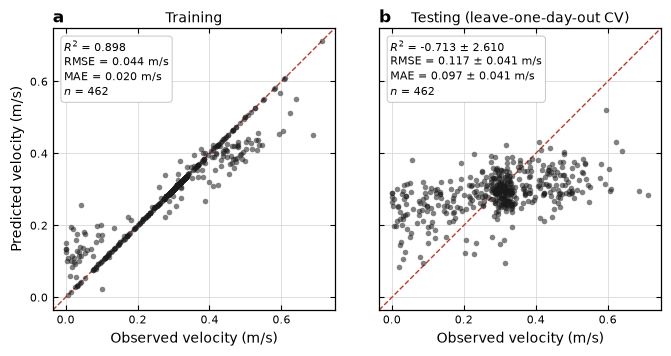

Training 1:1: R² = 0.8982, RMSE = 0.0441 m/s, MAE = 0.0199 m/s
Leave-one-day-out CV (fold mean ± std): R² = -0.7132 ± 2.6095, RMSE = 0.1168 ± 0.0410 m/s
Leave-one-day-out CV (pooled OOF):      R² = 0.2368, RMSE = 0.1207 m/s, MAE = 0.0918 m/s
Uncertainty calibration: lambda_global = 1.189
  Mean held-out std, raw / calibrated: 0.1005 / 0.1196 m/s
  By-year lambda: 2025=1.444, 2026=0.955


In [123]:
### 9) 3v Model Visualizations
# Compact literature 1:1 plots (training vs leave-one-survey-day-out CV)

# =====================================================================
# Training and leave-one-survey-day-out 1:1 plots
# =====================================================================
# Training panel uses in-sample predictions from the final model (all data).
# Test panel uses out-of-fold predictions from leave-one-survey-day-out CV,
# stored as y_pred_cv by the GP cell (uncorrected vel_1, inflated log-law noise).
# Summary metrics are derived here so this cell does not depend on names the
# GP cell no longer assigns (r2_3v, cv_r2_mean, ...).

if y_pred_cv is None:
    raise ValueError(
        "y_pred_cv is missing. Re-run the 3-input GP cell so leave-one-day-out "
        "predictions are collected, then re-run this cell."
    )

y_pred_cv = np.asarray(y_pred_cv, dtype=float)
cv_ok = np.isfinite(y_pred_cv)

r2_3v = r2_score(y_3v, y_pred_3v)
rmse_3v = np.sqrt(mean_squared_error(y_3v, y_pred_3v))
mae_3v = mean_absolute_error(y_3v, y_pred_3v)

cv_r2_arr = np.asarray(cv_r2_scores, dtype=float)
cv_rmse_arr = np.asarray(cv_rmse_scores, dtype=float)
cv_mae_arr = np.asarray(cv_mae_scores, dtype=float)
cv_r2_mean, cv_r2_std = float(cv_r2_arr.mean()), float(cv_r2_arr.std())
cv_rmse_mean, cv_rmse_std = float(cv_rmse_arr.mean()), float(cv_rmse_arr.std())
cv_mae_mean, cv_mae_std = float(cv_mae_arr.mean()), float(cv_mae_arr.std())

# Pooled OOF metrics (shown with the fold-mean ± std)
r2_cv_pooled = r2_score(y_3v[cv_ok], y_pred_cv[cv_ok])
rmse_cv_pooled = np.sqrt(mean_squared_error(y_3v[cv_ok], y_pred_cv[cv_ok]))
mae_cv_pooled = mean_absolute_error(y_3v[cv_ok], y_pred_cv[cv_ok])

INK = "#000000"
POINT = "#1a1a1a"
ONE_TO_ONE = "#c0392b"
GRID = "#d9d9d9"
SURFACE = "#ffffff"

_one_to_one_rc = {
    "font.family": "sans-serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
}


def _style_one_to_one(ax, y_obs, y_hat, panel, subtitle, stats, lims):
    ax.plot(lims, lims, color=ONE_TO_ONE, ls="--", lw=1.0, zorder=1)
    ax.scatter(y_obs, y_hat, s=16, c=POINT, alpha=0.55, linewidths=0,
               rasterized=True, zorder=2)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(panel, loc="left", fontweight="bold", fontsize=12, color=INK, pad=4)
    ax.set_title(subtitle, loc="center", fontsize=10, color=INK, pad=4)
    ax.set_xlabel("Observed velocity (m/s)", fontsize=10, color=INK)
    ax.tick_params(colors=INK, width=0.8, length=3.5)
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_color(INK)
        ax.spines[side].set_linewidth(0.9)
    ax.grid(True, color=GRID, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    ax.text(0.04, 0.96, stats, transform=ax.transAxes, va="top", ha="left",
            fontsize=8, color=INK, linespacing=1.35,
            bbox=dict(boxstyle="round,pad=0.28", facecolor="white",
                      edgecolor="#bdbdbd", linewidth=0.6))


lo = float(min(y_3v.min(), y_pred_3v.min(), y_pred_cv[cv_ok].min()))
hi = float(max(y_3v.max(), y_pred_3v.max(), y_pred_cv[cv_ok].max()))
pad = 0.05 * (hi - lo) if hi > lo else 0.05
lims = (lo - pad, hi + pad)

train_stats = (
    f"$R^2$ = {r2_3v:.3f}\n"
    f"RMSE = {rmse_3v:.3f} m/s\n"
    f"MAE = {mae_3v:.3f} m/s\n"
    f"$n$ = {len(y_3v)}"
)
cv_stats = (
    f"$R^2$ = {cv_r2_mean:.3f} $\\pm$ {cv_r2_std:.3f}\n"
    f"RMSE = {cv_rmse_mean:.3f} $\\pm$ {cv_rmse_std:.3f} m/s\n"
    f"MAE = {cv_mae_mean:.3f} $\\pm$ {cv_mae_std:.3f} m/s\n"
    f"$n$ = {int(cv_ok.sum())}"
)

with plt.rc_context(_one_to_one_rc):
    fig, axes = plt.subplots(1, 2, figsize=(6.9, 3.45), sharex=True, sharey=True,
                             facecolor=SURFACE, constrained_layout=True)
    _style_one_to_one(axes[0], y_3v, y_pred_3v, "a", "Training", train_stats, lims)
    _style_one_to_one(axes[1], y_3v[cv_ok], y_pred_cv[cv_ok], "b", "Testing (leave-one-day-out CV)", cv_stats, lims)
    axes[0].set_ylabel("Predicted velocity (m/s)", fontsize=10, color=INK)
    plt.show()

print(f"Training 1:1: R² = {r2_3v:.4f}, RMSE = {rmse_3v:.4f} m/s, MAE = {mae_3v:.4f} m/s")
print(f"Leave-one-day-out CV (fold mean ± std): R² = {cv_r2_mean:.4f} ± {cv_r2_std:.4f}, "
      f"RMSE = {cv_rmse_mean:.4f} ± {cv_rmse_std:.4f} m/s")
print(f"Leave-one-day-out CV (pooled OOF):      R² = {r2_cv_pooled:.4f}, "
      f"RMSE = {rmse_cv_pooled:.4f} m/s, MAE = {mae_cv_pooled:.4f} m/s")

if "lambda_global" in dir() and np.isfinite(lambda_global):
    print(f"Uncertainty calibration: lambda_global = {lambda_global:.3f}")
    if "y_std_cv" in dir() and y_std_cv is not None:
        std_ok = cv_ok & np.isfinite(y_std_cv) & (np.asarray(y_std_cv) > 0)
        mean_std_raw = float(np.mean(y_std_cv[std_ok]))
        print(f"  Mean held-out std, raw / calibrated: "
              f"{mean_std_raw:.4f} / {mean_std_raw * lambda_global:.4f} m/s")
    if "lambda_by_year" in dir() and lambda_by_year:
        print("  By-year lambda: " + ", ".join(
            f"{yr}={lam:.3f}" for yr, lam in sorted(lambda_by_year.items())
        ))
